# IDENTIFICAÇÃO DO PROBLEMA

OBJETIVO DO PROJETO:

Analisar a base de dados de animes da Crunchyroll para entender:
1. Qual a distribuição de notas (ratings) e engajamento (votos) dos animes na plataforma.
2. Quais são os animes mais populares e bem avaliados.
3. Se existe relação entre a quantidade de episódios e a nota média recebida.

Base de dados: [Crunchyroll Anime Ratings](https://www.kaggle.com/datasets/filipefilardi/crunchyroll-anime-ratings) (Kaggle), baixada automaticamente pelo `kagglehub`.

### 1. IMPORTAÇÃO DAS BIBLIOTECAS

In [12]:
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuração dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 2. CARREGAMENTO DOS DADOS

In [13]:
print("--- 2. CARREGAMENTO DOS DADOS ---")

# Baixa o diretório completo do dataset
dataset_path = kagglehub.dataset_download("filipefilardi/crunchyroll-anime-ratings")
print("Dataset baixado em:", dataset_path)

# Lista os arquivos disponíveis no diretório que foi baixado
arquivos = os.listdir(dataset_path)
print("Arquivos encontrados:", arquivos)

# Encontra o primeiro arquivo com extensão .csv dentro do diretório
csvs = [f for f in arquivos if f.endswith(".csv")]
if not csvs:
    raise FileNotFoundError(f"Nenhum arquivo .csv encontrado em {dataset_path}")
csv_file = csvs[0]
full_path = os.path.join(dataset_path, csv_file)
print(f"Carregando o arquivo: {csv_file}")

# Carrega o arquivo CSV criando a estrutura do DataFrame no Pandas
df = pd.read_csv(full_path)

# Exibe os 5 primeiros registros da tabela para conferência
print("\nPrimeiros 5 registros:")
print(df.head())

# Exibe a quantidade de linhas e colunas
print("\nDimensões do Dataset (Linhas, Colunas):", df.shape)

--- 2. CARREGAMENTO DOS DADOS ---
Using Colab cache for faster access to the 'crunchyroll-anime-ratings' dataset.
Dataset baixado em: /kaggle/input/crunchyroll-anime-ratings
Arquivos encontrados: ['animes.csv']
Carregando o arquivo: animes.csv

Primeiros 5 registros:
               anime                                     anime_url  \
0  Naruto Shippuuden  https://www.crunchyroll.com/naruto-shippuden   
1        Shugo Chara       https://www.crunchyroll.com/shugo-chara   
2             BLEACH            https://www.crunchyroll.com/bleach   
3             Naruto            https://www.crunchyroll.com/naruto   
4         Skip Beat!         https://www.crunchyroll.com/skip-beat   

                                           anime_img  episodes  votes  weight  \
0  https://img1.ak.crunchyroll.com/i/spire4/1c1df...       500  48518  233346   
1  https://img1.ak.crunchyroll.com/i/spire1/7c0c0...        51  33688  163641   
2  https://img1.ak.crunchyroll.com/i/spire2/52edb...       366  2390

### 3. ANÁLISE EXPLORATÓRIA E LIMPEZA

In [14]:
print("\n--- 3. ANÁLISE EXPLORATÓRIA E LIMPEZA ---")

# Exibe o tipo de dados de cada coluna (String, Float, Int)
print("\nInformações do DataFrame:")
df.info()

# Contagem de valores nulos (mostra só as colunas que têm nulos)
nulos = df.isnull().sum()
print("\nValores nulos por coluna:")
print(nulos[nulos > 0] if nulos.any() else "Nenhum valor nulo encontrado.")


--- 3. ANÁLISE EXPLORATÓRIA E LIMPEZA ---

Informações do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1255 entries, 0 to 1254
Data columns (total 41 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   anime                   1255 non-null   object 
 1   anime_url               1255 non-null   object 
 2   anime_img               1255 non-null   object 
 3   episodes                1255 non-null   int64  
 4   votes                   1255 non-null   int64  
 5   weight                  1255 non-null   int64  
 6   rate                    1255 non-null   float64
 7   rate_1                  1255 non-null   int64  
 8   rate_2                  1255 non-null   int64  
 9   rate_3                  1255 non-null   int64  
 10  rate_4                  1255 non-null   int64  
 11  rate_5                  1255 non-null   int64  
 12  genre_action            1255 non-null   float64
 13  genre_adventure        

In [15]:
# Tratamento e Limpeza dos Dados
linhas_inicio = len(df)

# 1. Converte as colunas numéricas ANTES de remover nulos
#    (a conversão com errors='coerce' pode gerar novos nulos)
for col in ['rate', 'votes', 'episodes']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 2. Remove duplicatas e registros sem nome do anime, nota ou quantidade de votos
df = df.drop_duplicates()
df = df.dropna(subset=['anime', 'rate', 'votes'])
print(f"Linhas removidas na limpeza: {linhas_inicio - len(df)} (de {linhas_inicio})")

# 3. Animes sem nenhum voto aparecem com nota 0. Isso é ausência de avaliação,
#    não uma nota ruim, então eles ficam fora das análises de nota.
sem_votos = (df['votes'] == 0).sum()
print(f"Animes sem votos (nota 0 por falta de avaliação): {sem_votos}")
print("Notas 0 mesmo com votos (deve ser 0):", ((df['rate'] == 0) & (df['votes'] > 0)).sum())
df_av = df[df['votes'] > 0].copy()

# 4. Episódios = 0 parece indicar "não informado" (muitos títulos têm esse valor),
#    então é tratado como ausente nas análises que usam episódios.
sem_ep = (df_av['episodes'] == 0).sum()
print(f"Animes avaliados com 0 episódios (tratados como não informado): {sem_ep}")
df_av['episodes'] = df_av['episodes'].replace(0, float('nan'))

# Resumo estatístico numérico (média, desvio padrão, mínimo, máximo e quartis)
print("\nResumo Estatístico (animes com votos):")
print(df_av[['rate', 'votes', 'episodes']].describe())

Linhas removidas na limpeza: 0 (de 1255)
Animes sem votos (nota 0 por falta de avaliação): 20
Notas 0 mesmo com votos (deve ser 0): 0
Animes avaliados com 0 episódios (tratados como não informado): 484

Resumo Estatístico (animes com votos):
              rate         votes     episodes
count  1235.000000   1235.000000   751.000000
mean      4.147028    349.227530    25.355526
std       0.727950   2064.130158    54.199878
min       1.000000      1.000000     1.000000
25%       3.770000     12.000000    12.000000
50%       4.360000     42.000000    13.000000
75%       4.690000    142.500000    24.000000
max       5.000000  48518.000000  1135.000000


### 4. VISUALIZAÇÃO DOS DADOS


--- 4. VISUALIZAÇÕES DOS DADOS ---


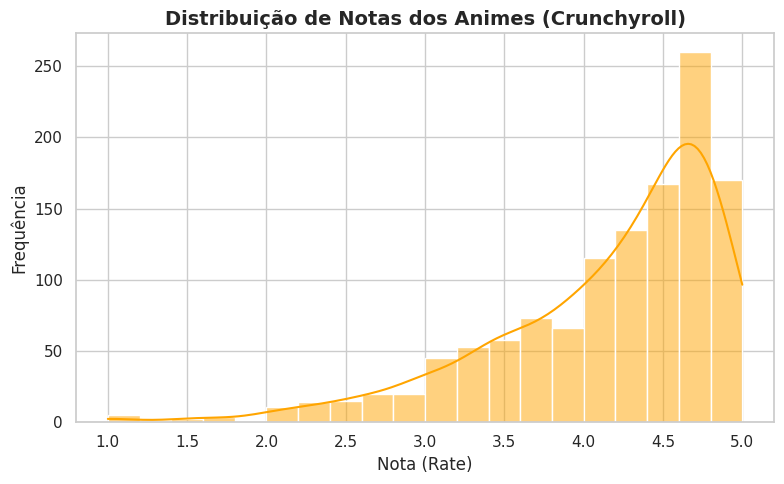

In [16]:
print("\n--- 4. VISUALIZAÇÕES DOS DADOS ---")

# Gráfico 1: Histograma da distribuição de notas dos animes (apenas animes com votos)
plt.figure(figsize=(8, 5))
sns.histplot(df_av['rate'], bins=20, kde=True, color='orange',
             kde_kws={'clip': (df_av['rate'].min(), 5)})
plt.title('Distribuição de Notas dos Animes (Crunchyroll)', fontsize=14, fontweight='bold')
plt.xlabel('Nota (Rate)')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()

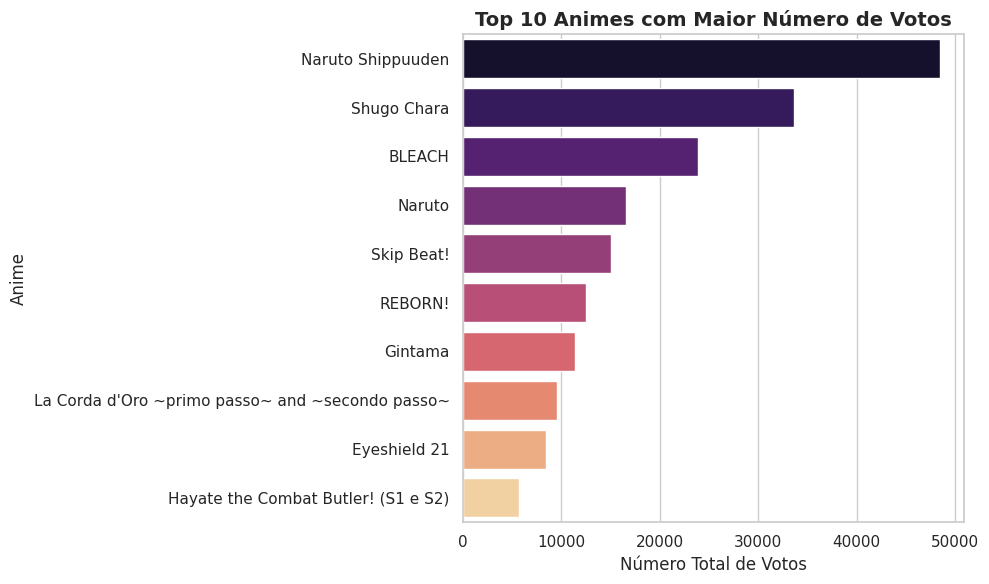

In [17]:
# Gráfico 2: Seleciona os 10 animes com maior quantidade de votos no catálogo
top_voted = df_av.sort_values(by='votes', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_voted, x='votes', y='anime', hue='anime', palette='magma', legend=False)
plt.title('Top 10 Animes com Maior Número de Votos', fontsize=14, fontweight='bold')
plt.xlabel('Número Total de Votos')
plt.ylabel('Anime')
plt.tight_layout()
plt.show()

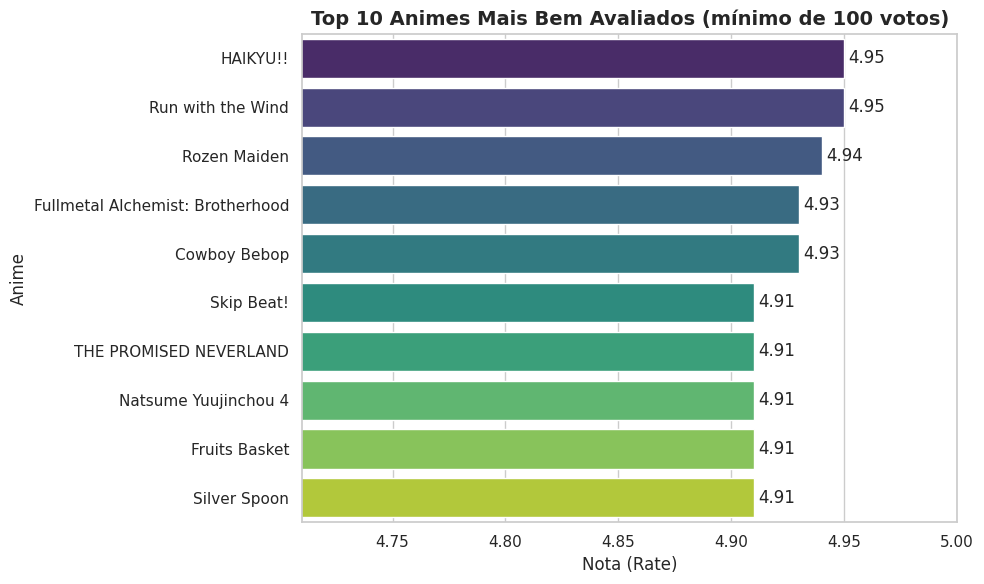

In [18]:
# Gráfico 3: Os 10 animes mais bem avaliados, considerando só títulos com votos suficientes.
# Sem esse corte, um anime com poucos votos e nota 5.0 apareceria no topo.
# O valor de 100 votos é uma escolha deste projeto e pode ser ajustado.
MIN_VOTOS = 100
top_rated = (df_av[df_av['votes'] >= MIN_VOTOS]
             .sort_values(by=['rate', 'votes'], ascending=False)
             .head(10))

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=top_rated, x='rate', y='anime', hue='anime', palette='viridis', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)
# O eixo não começa em zero de propósito, para mostrar a diferença entre notas muito próximas
plt.xlim(top_rated['rate'].min() - 0.2, 5.0)
plt.title(f'Top 10 Animes Mais Bem Avaliados (mínimo de {MIN_VOTOS} votos)', fontsize=14, fontweight='bold')
plt.xlabel('Nota (Rate)')
plt.ylabel('Anime')
plt.tight_layout()
plt.show()

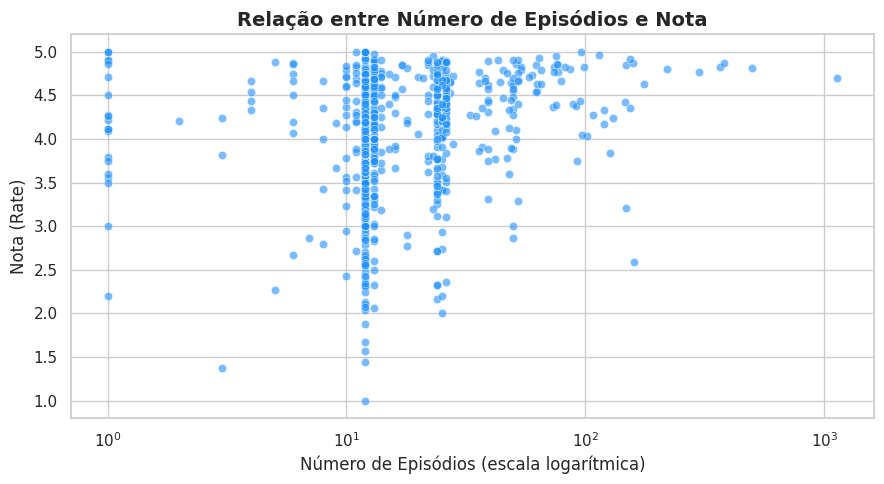

In [19]:
# Gráfico 4: Relação entre a quantidade de episódios e a nota recebida (Gráfico de Dispersão)
# Só entram animes com episódios informados; o eixo x usa escala logarítmica
# porque poucos títulos têm centenas de episódios e achatariam o resto do gráfico.
df_ep = df_av.dropna(subset=['episodes'])

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_ep, x='episodes', y='rate', alpha=0.6, color='dodgerblue')
plt.xscale('log')
plt.title('Relação entre Número de Episódios e Nota', fontsize=14, fontweight='bold')
plt.xlabel('Número de Episódios (escala logarítmica)')
plt.ylabel('Nota (Rate)')
plt.tight_layout()
plt.show()

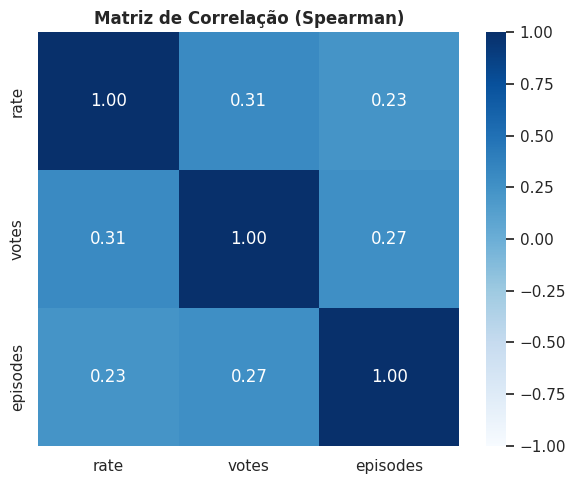

In [20]:
# Gráfico 5: Matriz de Correlação entre variáveis numéricas
# - Usa Spearman (por ranking), mais adequado que Pearson para votos e episódios,
#   que têm poucos valores muito altos.
# - A coluna 'weight' fica de fora: nos primeiros registros ela é igual a votos x nota,
#   então só repetiria a informação de 'votes'.
numeric_cols = df_ep[['rate', 'votes', 'episodes']].dropna()
correlation = numeric_cols.corr(method='spearman')

plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap='Blues', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação (Spearman)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 5. RELATÓRIO FINAL COM CONCLUSÕES

In [21]:
# Cálculos para o relatório: todos os números abaixo saem dos dados.
def br(n, casas=0):
    """Formata número no padrão brasileiro (ponto nos milhares, vírgula nos decimais)."""
    return f"{n:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def forca(r):
    a = abs(r)
    return "muito fraca" if a < 0.1 else "fraca" if a < 0.3 else "moderada" if a < 0.5 else "forte"

def sentido(r):
    return "positiva" if r > 0 else "negativa"

total_catalogo = len(df)
n_av = len(df_av)
media_nota = df_av['rate'].mean()
mediana_nota = df_av['rate'].median()
pct_acima_4 = (df_av['rate'] > 4).mean() * 100

mediana_votos = df_av['votes'].median()
media_votos = df_av['votes'].mean()
top_anime = top_voted.iloc[0]['anime']
total_votos_top1 = top_voted.iloc[0]['votes']
n_top10pct = max(1, int(n_av * 0.10))
share_top10pct = df_av.nlargest(n_top10pct, 'votes')['votes'].sum() / df_av['votes'].sum() * 100

r_ep_nota = correlation.loc['rate', 'episodes']
r_votos_nota = correlation.loc['rate', 'votes']
r_votos_ep = correlation.loc['votes', 'episodes']

linha_top_nota = ""
if len(top_rated) > 0:
    melhor = top_rated.iloc[0]
    linha_top_nota = (f"   - Entre os títulos com pelo menos {MIN_VOTOS} votos, o mais bem avaliado foi "
                      f"'{melhor['anime']}', com nota {br(melhor['rate'], 2)}.\n")

if abs(r_ep_nota) < 0.3:
    leitura_ep = "Nesta base, a quantidade de episódios explica pouco da nota recebida."
else:
    leitura_ep = "Há uma relação relevante entre a quantidade de episódios e a nota nesta base."

print(f"""
1. PERFIL GERAL E NOTAS (AVALIAÇÃO):
   - {br(n_av)} dos {br(total_catalogo)} animes do catálogo têm pelo menos um voto e entram na análise de notas.
   - A nota média foi {br(media_nota, 2)} e a mediana {br(mediana_nota, 2)} (escala de até 5,0).
   - {pct_acima_4:.0f}% dos animes avaliados têm nota acima de 4,0, o que se vê na concentração à direita do histograma.
   - Notas altas parecem comuns na plataforma. Uma possível explicação, não testada aqui, é que
     as pessoas tendem a avaliar melhor o que escolheram assistir.

2. ENGAJAMENTO E POPULARIDADE (VOTOS):
   - O anime mais votado foi '{top_anime}', com {br(total_votos_top1)} votos.
   - A mediana de votos é {br(mediana_votos)}, enquanto a média é {br(media_votos)}: poucos títulos têm muitos votos.
   - Os 10% de animes mais votados concentram {share_top10pct:.0f}% do total de votos.
{linha_top_nota}
3. CORRELAÇÕES (Spearman, {br(len(numeric_cols))} animes com votos e episódios informados):
   - Episódios x nota: {br(r_ep_nota, 2)} (correlação {sentido(r_ep_nota)} {forca(r_ep_nota)}). {leitura_ep}
   - Votos x nota: {br(r_votos_nota, 2)} (correlação {sentido(r_votos_nota)} {forca(r_votos_nota)}).
   - Votos x episódios: {br(r_votos_ep, 2)} (correlação {sentido(r_votos_ep)} {forca(r_votos_ep)}).
   - Correlação não indica causa: os números mostram associação, não explicam o motivo.

4. LIMITAÇÕES:
   - As notas vêm de usuários da plataforma, não de crítica especializada.
   - Animes sem votos (nota 0) foram excluídos, e episódios = 0 foi tratado como "não informado".
   - O corte de {MIN_VOTOS} votos no ranking de notas é uma escolha do projeto.
""")


1. PERFIL GERAL E NOTAS (AVALIAÇÃO):
   - 1.235 dos 1.255 animes do catálogo têm pelo menos um voto e entram na análise de notas.
   - A nota média foi 4,15 e a mediana 4,36 (escala de até 5,0).
   - 66% dos animes avaliados têm nota acima de 4,0, o que se vê na concentração à direita do histograma.
   - Notas altas parecem comuns na plataforma. Uma possível explicação, não testada aqui, é que
     as pessoas tendem a avaliar melhor o que escolheram assistir.

2. ENGAJAMENTO E POPULARIDADE (VOTOS):
   - O anime mais votado foi 'Naruto Shippuuden', com 48.518 votos.
   - A mediana de votos é 42, enquanto a média é 349: poucos títulos têm muitos votos.
   - Os 10% de animes mais votados concentram 80% do total de votos.
   - Entre os títulos com pelo menos 100 votos, o mais bem avaliado foi 'HAIKYU!!', com nota 4,95.

3. CORRELAÇÕES (Spearman, 751 animes com votos e episódios informados):
   - Episódios x nota: 0,23 (correlação positiva fraca). Nesta base, a quantidade de episódios expl